# Lab 01 · 역전파를 밑바닥부터: 스칼라 autograd → 행렬 미분 → PyTorch

**이 실습이 다루는 자료** ([필독 목록](../READING_LIST.md) · [실습 가이드](../PRACTICE.md))

| 절 | 직접 확인할 것 | 관련 자료 |
|---|---|---|
| 1 | 미분의 정의를 숫자로 확인 (수치 미분) | [미적분·최적화](../../00_Foundations/02_calculus-optimization.md) |
| 2–3 | 연쇄법칙을 자동으로 적용하는 60줄짜리 autograd 엔진 | Rumelhart, Hinton, Williams (1986); Karpathy *micrograd* 영상 |
| 4 | 같은 계산을 행렬로: $\partial L/\partial W = X^\top\delta$ | *The Matrix Calculus You Need For Deep Learning* |
| 5 | 내 구현 = PyTorch `loss.backward()` 임을 확인하고 학습 | PyTorch 튜토리얼 |

**소요 시간**: 90분 · **패키지**: numpy, matplotlib, scikit-learn, torch  
이 노트북의 `Value` 클래스는 Karpathy의 [micrograd](https://github.com/karpathy/micrograd)(MIT)와 같은 발상을 따라 새로 쓴 교육용 구현입니다. 영상과 함께 보면 가장 좋습니다.

In [1]:
import math, numpy as np, matplotlib.pyplot as plt
rng = np.random.default_rng(0)
plt.rcParams.update({"figure.figsize": (6, 3.5), "figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

## 1. 미분 = "입력을 아주 조금 바꾸면 출력이 얼마나 변하는가"

✍️ **예측**: $f(x)=3x^2-4x+5$ 의 $x=3$ 에서의 기울기는? (손으로 계산한 뒤 실행)

In [2]:
f = lambda x: 3 * x**2 - 4 * x + 5
x, h = 3.0, 1e-5
print("수치 미분 (f(x+h) - f(x-h)) / 2h =", (f(x + h) - f(x - h)) / (2 * h), " | 해석적 미분 6x - 4 =", 6 * x - 4)

수치 미분 (f(x+h) - f(x-h)) / 2h = 14.000000000180533  | 해석적 미분 6x - 4 = 14.0


변수가 여러 개면 변수마다 따로 흔들어 보면 됩니다. 이 "하나씩 흔들기"는 느리지만 **정답지**로 쓸 수 있어서, 이후 모든 구현을 이것으로 검증합니다(gradient check).

## 2. 연쇄법칙을 자동으로: 60줄 autograd

아이디어 (Rumelhart et al., 1986)
1. 계산을 덧셈·곱셈 같은 **작은 연산의 그래프**로 기록한다.
2. 각 연산은 "출력의 기울기를 받아 입력의 기울기로 넘기는 법"(국소 미분)만 안다.
3. 출력에서 시작해 그래프를 **거꾸로** 따라가며 곱해 나간다 → 모든 입력의 기울기가 한 번에 나온다.

In [3]:
class Value:
    """스칼라 하나와 그 기울기를 담는 노드"""
    def __init__(self, data, parents=(), op=""):
        self.data, self.grad = float(data), 0.0
        self._parents, self._op, self._backward = parents, op, (lambda: None)

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), "+")
        def backward():                      # d(a+b)/da = 1, d(a+b)/db = 1
            self.grad += out.grad
            other.grad += out.grad
        out._backward = backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "*")
        def backward():                      # d(ab)/da = b, d(ab)/db = a
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = backward
        return out

    def __pow__(self, k):                    # k는 상수
        out = Value(self.data**k, (self,), f"**{k}")
        def backward():
            self.grad += k * self.data ** (k - 1) * out.grad
        out._backward = backward
        return out

    def tanh(self):
        t = math.tanh(self.data)
        out = Value(t, (self,), "tanh")
        def backward():                      # d tanh(x)/dx = 1 - tanh(x)^2
            self.grad += (1 - t**2) * out.grad
        out._backward = backward
        return out

    def backward(self):
        order, seen, stack = [], set(), [(self, False)]
        while stack:                         # 위상 정렬 (재귀 없이)
            node, done = stack.pop()
            if done: order.append(node); continue
            if node in seen: continue
            seen.add(node); stack.append((node, True))
            stack.extend((p, False) for p in node._parents)
        self.grad = 1.0                      # dL/dL = 1
        for node in reversed(order):         # 출력 → 입력 방향
            node._backward()

    __radd__ = __add__
    __rmul__ = __mul__
    def __neg__(self): return self * -1
    def __sub__(self, other): return self + (-other)
    def __rsub__(self, other): return other + (-self)
    def __truediv__(self, other): return self * (other if isinstance(other, Value) else Value(other)) ** -1
    def __repr__(self): return f"Value(data={self.data:.4f}, grad={self.grad:.4f})"

`+=` 로 누적하는 이유: 한 값이 여러 곳에 쓰이면 각 경로의 기울기를 **더해야** 하기 때문입니다(다변수 연쇄법칙).

✍️ **예측**: $L=(wx+b-y)^2$, $w=2,\ x=3,\ b=1,\ y=10$ 일 때 $\partial L/\partial w$ 는? 손으로 풀고 확인하세요.

In [4]:
w, x, b, y = Value(2.0), Value(3.0), Value(1.0), Value(10.0)
L = (w * x + b - y) ** 2
L.backward()
print("L =", L.data, "| dL/dw =", w.grad, "| dL/db =", b.grad, "| dL/dx =", x.grad)
# 손 계산: 오차 e = wx+b-y = -3,  dL/dw = 2e·x = -18,  dL/db = 2e = -6,  dL/dx = 2e·w = -12

L = 9.0 | dL/dw = -18.0 | dL/db = -6.0 | dL/dx = -12.0


## 3. Gradient check: 내 구현을 수치 미분으로 검증

새 연산을 만들 때마다 반드시 하는 절차입니다. 논문 구현이 이상할 때도 가장 먼저 해 볼 일입니다.

In [5]:
def expression(a, b, c):
    return ((a * b + c).tanh() * a - b / c) ** 2 + a * 0.5

vals = [0.7, -1.3, 2.1]
nodes = [Value(v) for v in vals]
out = expression(*nodes); out.backward()
h = 1e-6
for i, name in enumerate("abc"):
    up = vals.copy(); up[i] += h; dn = vals.copy(); dn[i] -= h
    numeric = (expression(*map(Value, up)).data - expression(*map(Value, dn)).data) / (2 * h)
    print(f"d/d{name}: autograd = {nodes[i].grad:+.6f}   numeric = {numeric:+.6f}")

d/da: autograd = +1.816543   numeric = +1.816543
d/db: autograd = -0.778428   numeric = -0.778428
d/dc: autograd = -0.186520   numeric = -0.186520


## 4. 같은 계산을 행렬로

스칼라 그래프는 이해하기 좋지만 느립니다. 실제 프레임워크는 **텐서 단위**로 같은 일을 합니다. 2 → 8 → 1 구조의 작은 신경망을 예로 듭니다.

$$Z_1=XW_1+b_1,\quad A_1=\tanh(Z_1),\quad \hat y=\tanh(A_1W_2+b_2),\quad L=\tfrac1N\sum(\hat y-y)^2$$

역전파는 뒤에서부터 "오차 신호 $\delta$"를 넘기는 과정입니다.

$$\delta_2=\tfrac{2}{N}(\hat y-y)\odot(1-\hat y^2),\quad \frac{\partial L}{\partial W_2}=A_1^\top\delta_2,\quad \delta_1=(\delta_2W_2^\top)\odot(1-A_1^2),\quad \frac{\partial L}{\partial W_1}=X^\top\delta_1$$

✍️ **예측**: $\partial L/\partial W_1$ 의 shape은? (힌트: 기울기의 shape은 항상 그 파라미터의 shape과 같다)

In [6]:
from sklearn.datasets import make_moons
X, y01 = make_moons(n_samples=60, noise=0.15, random_state=0)
y = (2 * y01 - 1).astype(float)[:, None]                 # 라벨을 -1 / +1 로
H = 8
params = {"W1": rng.normal(0, 0.8, (2, H)), "b1": np.zeros((1, H)), "W2": rng.normal(0, 0.8, (H, 1)), "b2": np.zeros((1, 1))}

def forward_backward(p, X, y):
    N = len(X)
    Z1 = X @ p["W1"] + p["b1"]; A1 = np.tanh(Z1)
    out = np.tanh(A1 @ p["W2"] + p["b2"])
    loss = np.mean((out - y) ** 2)
    d2 = (2 / N) * (out - y) * (1 - out**2)                 # δ2
    d1 = (d2 @ p["W2"].T) * (1 - A1**2)                     # δ1
    grads = {"W2": A1.T @ d2, "b2": d2.sum(0, keepdims=True), "W1": X.T @ d1, "b1": d1.sum(0, keepdims=True)}
    return loss, grads

loss, grads = forward_backward(params, X, y)
print("loss =", round(loss, 4), "| shapes:", {k: v.shape for k, v in grads.items()})

loss = 1.1634 | shapes: {'W2': (8, 1), 'b2': (1, 1), 'W1': (2, 8), 'b1': (1, 8)}


같은 신경망을 3절의 `Value` 엔진으로도 만들어, 행렬 공식이 맞는지 **원소 하나하나** 대조합니다.

In [7]:
def loss_with_values(p, X, y):
    W1 = [[Value(v) for v in row] for row in p["W1"]]; b1 = [Value(v) for v in p["b1"][0]]
    W2 = [Value(v) for v in p["W2"][:, 0]]; b2 = Value(p["b2"][0, 0])
    total = Value(0.0)
    for xi, yi in zip(X, y[:, 0]):
        hidden = [(xi[0] * W1[0][j] + xi[1] * W1[1][j] + b1[j]).tanh() for j in range(H)]
        out = sum((hj * w2j for hj, w2j in zip(hidden, W2)), b2).tanh()
        total = total + (out - yi) ** 2
    L = total / len(X); L.backward()
    return L.data, np.array([[v.grad for v in row] for row in W1]), np.array([v.grad for v in W2])

L_val, gW1_val, gW2_val = loss_with_values(params, X, y)
print("loss 일치:", np.isclose(L_val, loss))
print("dL/dW1 최대 차이:", np.abs(gW1_val - grads["W1"]).max(), "| dL/dW2 최대 차이:", np.abs(gW2_val - grads["W2"][:, 0]).max())

loss 일치: True
dL/dW1 최대 차이: 8.326672684688674e-17 | dL/dW2 최대 차이: 2.220446049250313e-16


## 5. PyTorch는 이 일을 대신해 준다

`requires_grad=True` 인 텐서로 순전파를 쓰면, `loss.backward()` 가 2~4절에서 한 일을 수행합니다.

In [8]:
import torch
tp = {k: torch.tensor(v, requires_grad=True) for k, v in params.items()}
Xt, yt = torch.tensor(X), torch.tensor(y)
out = torch.tanh(torch.tanh(Xt @ tp["W1"] + tp["b1"]) @ tp["W2"] + tp["b2"])
torch_loss = ((out - yt) ** 2).mean()
torch_loss.backward()
for k in params:
    print(f"{k}: 직접 계산 vs PyTorch 최대 차이 = {np.abs(grads[k] - tp[k].grad.numpy()).max():.2e}")

W1: 직접 계산 vs PyTorch 최대 차이 = 1.11e-16
b1: 직접 계산 vs PyTorch 최대 차이 = 2.22e-16
W2: 직접 계산 vs PyTorch 최대 차이 = 3.33e-16
b2: 직접 계산 vs PyTorch 최대 차이 = 1.11e-16


세 가지 방법(스칼라 autograd, 행렬 공식, PyTorch)이 같은 기울기를 냅니다. 이제 그 기울기로 **경사하강**을 합니다.

✍️ **예측**: 학습률을 0.5에서 5로 올리면 어떤 일이 생길까요?

lr=0.05: 마지막 loss = 0.0229
lr=0.5: 마지막 loss = 0.0007


lr=5.0: 마지막 loss = 0.3333


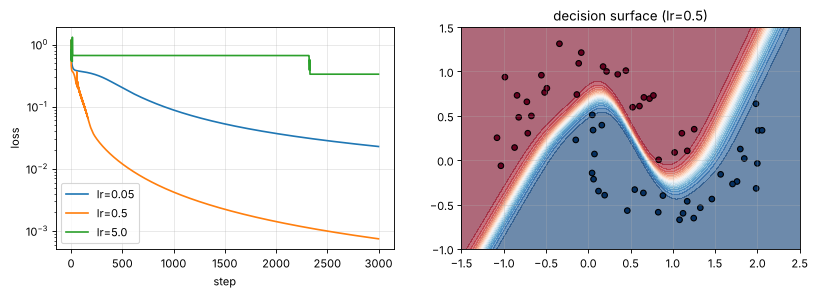

train accuracy (lr=0.5) = 1.0


In [9]:
def train(lr, steps=3000, seed=0):
    r = np.random.default_rng(seed)
    p = {"W1": r.normal(0, 0.8, (2, H)), "b1": np.zeros((1, H)), "W2": r.normal(0, 0.8, (H, 1)), "b2": np.zeros((1, 1))}
    history = []
    for _ in range(steps):
        loss, g = forward_backward(p, X, y)
        for k in p: p[k] -= lr * g[k]                      # θ ← θ − η∇L
        history.append(loss)
    return p, history

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for lr in [0.05, 0.5, 5.0]:
    p, hist = train(lr); axes[0].plot(hist, label=f"lr={lr}")
    print(f"lr={lr}: 마지막 loss = {hist[-1]:.4f}")
axes[0].set_yscale("log"); axes[0].set_xlabel("step"); axes[0].set_ylabel("loss"); axes[0].legend()
p, _ = train(0.5)
xx, yy = np.meshgrid(np.linspace(-1.5, 2.5, 200), np.linspace(-1, 1.5, 200)); grid = np.c_[xx.ravel(), yy.ravel()]
pred = np.tanh(np.tanh(grid @ p["W1"] + p["b1"]) @ p["W2"] + p["b2"]).reshape(xx.shape)
axes[1].contourf(xx, yy, pred, levels=20, cmap="RdBu", alpha=0.6); axes[1].scatter(X[:, 0], X[:, 1], c=y[:, 0], cmap="RdBu", edgecolor="k", s=25)
axes[1].set_title("decision surface (lr=0.5)"); plt.show()
acc = np.mean(np.sign(np.tanh(np.tanh(X @ p["W1"] + p["b1"]) @ p["W2"] + p["b2"])) == y)
print("train accuracy (lr=0.5) =", acc)

학습률이 너무 작으면 느리고, 너무 크면 손실이 내려가지 않고 튑니다. [신경망 문서](../../00_Foundations/05_neural-networks.md)의 "손실이 줄지 않으면 가장 먼저 학습률을 의심한다"가 이 그림입니다.

---
## 직접 해보기

1. **(연산 추가)** `Value`에 `exp()`와 `log()`를 추가하고, 시그모이드 $\sigma(z)=1/(1+e^{-z})$ 와 이진 교차 엔트로피 $-[y\log p+(1-y)\log(1-p)]$ 를 만들어 $\partial L/\partial z$ 를 구하세요. 유명한 결과 $p-y$ 와 같은지 확인하세요.
2. **(softmax)** 점수 벡터 $z$ 에 대해 softmax + 교차 엔트로피의 기울기가 $p-\text{onehot}(y)$ 임을 수치 미분으로 확인하세요.
3. **(생각해 보기)** `backward()` 에서 `self.grad += ...` 를 `self.grad = ...` 로 바꾸면 어떤 식에서 틀릴까요? 예를 하나 만들어 보세요.

In [10]:
# TODO 1: Value.exp, Value.log 를 추가하고 dL/dz == p - y 확인

# TODO 2: softmax + cross-entropy 의 기울기를 수치 미분으로 확인

# TODO 3: += 를 = 로 바꾸면 틀리는 예

---
## 정답 예시 (먼저 풀어 본 뒤 확인)

In [11]:
# 1. exp, log 추가
def v_exp(self):
    out = Value(math.exp(self.data), (self,), "exp")
    def backward(): self.grad += out.data * out.grad            # d e^x/dx = e^x
    out._backward = backward
    return out
def v_log(self):
    out = Value(math.log(self.data), (self,), "log")
    def backward(): self.grad += (1 / self.data) * out.grad     # d ln x/dx = 1/x
    out._backward = backward
    return out
Value.exp, Value.log = v_exp, v_log
Value.__rtruediv__ = lambda self, other: Value(other) * self ** -1     # "숫자 / Value" 를 위해 필요

z, target = Value(0.3), 1.0
prob = 1 / (1 + (-z).exp())                                     # 시그모이드
bce = -(target * prob.log() + (1 - target) * (1 - prob).log())  # 이진 교차 엔트로피
bce.backward()
print(f"autograd dL/dz = {z.grad:.6f}   p - y = {prob.data - target:.6f}")

autograd dL/dz = -0.425557   p - y = -0.425557


In [12]:
# 2. softmax + cross-entropy: dL/dz = p - onehot(y)
def ce(zvec, label):
    zvec = zvec - zvec.max(); p = np.exp(zvec) / np.exp(zvec).sum()
    return -np.log(p[label]), p
zvec, label = np.array([1.0, -0.5, 2.0, 0.1]), 2
loss0, p = ce(zvec, label)
numeric = np.array([(ce(zvec + 1e-6 * np.eye(4)[i], label)[0] - ce(zvec - 1e-6 * np.eye(4)[i], label)[0]) / 2e-6 for i in range(4)])
print("numeric   :", numeric.round(5)); print("p - onehot:", (p - np.eye(4)[label]).round(5))

numeric   : [ 0.22999  0.05132 -0.37482  0.09351]
p - onehot: [ 0.22999  0.05132 -0.37482  0.09351]


In [13]:
# 3. 같은 값을 두 번 쓰는 식: y = a * a  →  dy/da = 2a.  '=' 로 덮어쓰면 a 가 한 번만 반영되어 틀린다.
a = Value(3.0); yv = a * a; yv.backward()
print("a*a 의 기울기 (올바른 값 6):", a.grad)

a*a 의 기울기 (올바른 값 6): 6.0


**1번에 대한 보충**: `1 / Value` 처럼 왼쪽이 파이썬 숫자인 나눗셈은 `__rtruediv__` 가 따로 필요합니다. 연산을 직접 추가하다 보면 이런 "빠진 연산"을 자주 만나는데, 그 과정이 autograd를 이해하는 가장 빠른 길입니다.

---
## 논문으로 돌아가기

| 방금 한 것 | 논문·자료에서 확인할 곳 |
|---|---|
| 2절 `backward()` | Rumelhart et al. (1986): 출력층의 오차를 은닉층으로 "거꾸로 전달"하는 식. 논문의 $\delta$ 가 이 노트북의 `d2`, `d1` |
| 4절 행렬 공식 | *The Matrix Calculus You Need For Deep Learning* 의 벡터 연쇄법칙, [신경망 문서](../../00_Foundations/05_neural-networks.md)의 학습 루프 |
| 5절 학습률 실험 | Karpathy *A Recipe for Training Neural Networks* — "먼저 작은 데이터에 과적합시켜 보라" |

## 기억 점검

1. 역전파를 한 문장으로 설명하면?
2. 한 변수가 그래프에서 두 번 쓰이면 기울기는 어떻게 합쳐지나?
3. $Z = XW$ 일 때 $\partial L/\partial W$ 를 $\delta=\partial L/\partial Z$ 로 쓰면? shape이 맞는지로 검산하는 법은?
4. gradient check란 무엇이고 언제 쓰나?
5. 시그모이드 + 이진 교차 엔트로피의 $\partial L/\partial z$ 는?

<details><summary>답 확인</summary>

1. 계산 그래프를 출력에서 입력 방향으로 따라가며 각 연산의 국소 미분을 곱해(연쇄법칙) 모든 파라미터의 기울기를 한 번에 구하는 알고리즘.
2. 각 경로에서 온 기울기를 더한다(그래서 `+=`).
3. $X^\top\delta$. $X$ 가 (N, d), $\delta$ 가 (N, h) 이면 결과는 (d, h) 로 $W$ 와 shape이 같다.
4. 해석적으로(또는 autograd로) 구한 기울기를 수치 미분 $(f(x+h)-f(x-h))/2h$ 과 비교하는 검증. 새 층·손실을 구현했을 때.
5. $p-y$ (예측 확률 − 정답).
</details>